# Sentinel-1 RTC flood mapping (Planetary Computer)

Companion to `scripts/planetary_computer_s1.py`: same search and Subset download, then mapped with `eo_stac.viz`.

Needs `jupyter` and `planetary-computer`, e.g. `uv run --extra bench --with jupyter jupyter lab`.

In [1]:
from pathlib import Path

import numpy as np
import planetary_computer
import rioxarray
import xarray as xr

from eo_stac import STACSource, download_items, search_items, viz

In [2]:
S1_OUT = Path("../data/s1_rtc")
S1_BBOX = [-0.765953, 45.754828, -0.548630, 45.863477]

s1 = search_items(
    STACSource.from_url("https://planetarycomputer.microsoft.com/api/stac/v1"),
    collections=["sentinel-1-rtc"],
    bbox=S1_BBOX,
    datetime="2026-01-15/2026-03-01",
)
print(len(s1), "items")
s1[["item_id", "datetime"]].head()

26 items


,item_id,datetime
0,S1A_IW_GRDH_1SDV_20260301T060818_20260301T0608...,2026-03-01 06:08:31.238165+00:00
1,S1C_IW_GRDH_1SDV_20260224T175529_20260224T1755...,2026-02-24 17:55:42.235149+00:00
2,S1C_IW_GRDH_1SDV_20260224T175504_20260224T1755...,2026-02-24 17:55:17.235482+00:00
3,S1C_IW_GRDH_1SDV_20260223T060734_20260223T0607...,2026-02-23 06:07:46.540939+00:00
4,S1A_IW_GRDH_1SDV_20260222T061630_20260222T0616...,2026-02-22 06:16:43.046275+00:00


In [3]:
s1 = download_items(
    s1, S1_OUT, assets=["vv", "vh"], bbox=S1_BBOX, sign=planetary_computer.sign
)

Downloading: 100%|██████████| 52/52 [00:47<00:00,  1.11file/s]


### Footprints and thumbnails

In [4]:
viz.plot_footprints(s1, column=None)

In [5]:
viz.plot_thumbnails(s1, max_items=6, sign=planetary_computer.sign)

### Quick view of one Subset

Backscatter is linear power; open water is dark.

['2026-01-17', '2026-01-18', '2026-01-19', '2026-01-23', '2026-01-24', '2026-01-25', '2026-01-29', '2026-01-30', '2026-01-31', '2026-02-04', '2026-02-05', '2026-02-06', '2026-02-10', '2026-02-11', '2026-02-12', '2026-02-16', '2026-02-17', '2026-02-18', '2026-02-22', '2026-02-23', '2026-02-24', '2026-03-01']



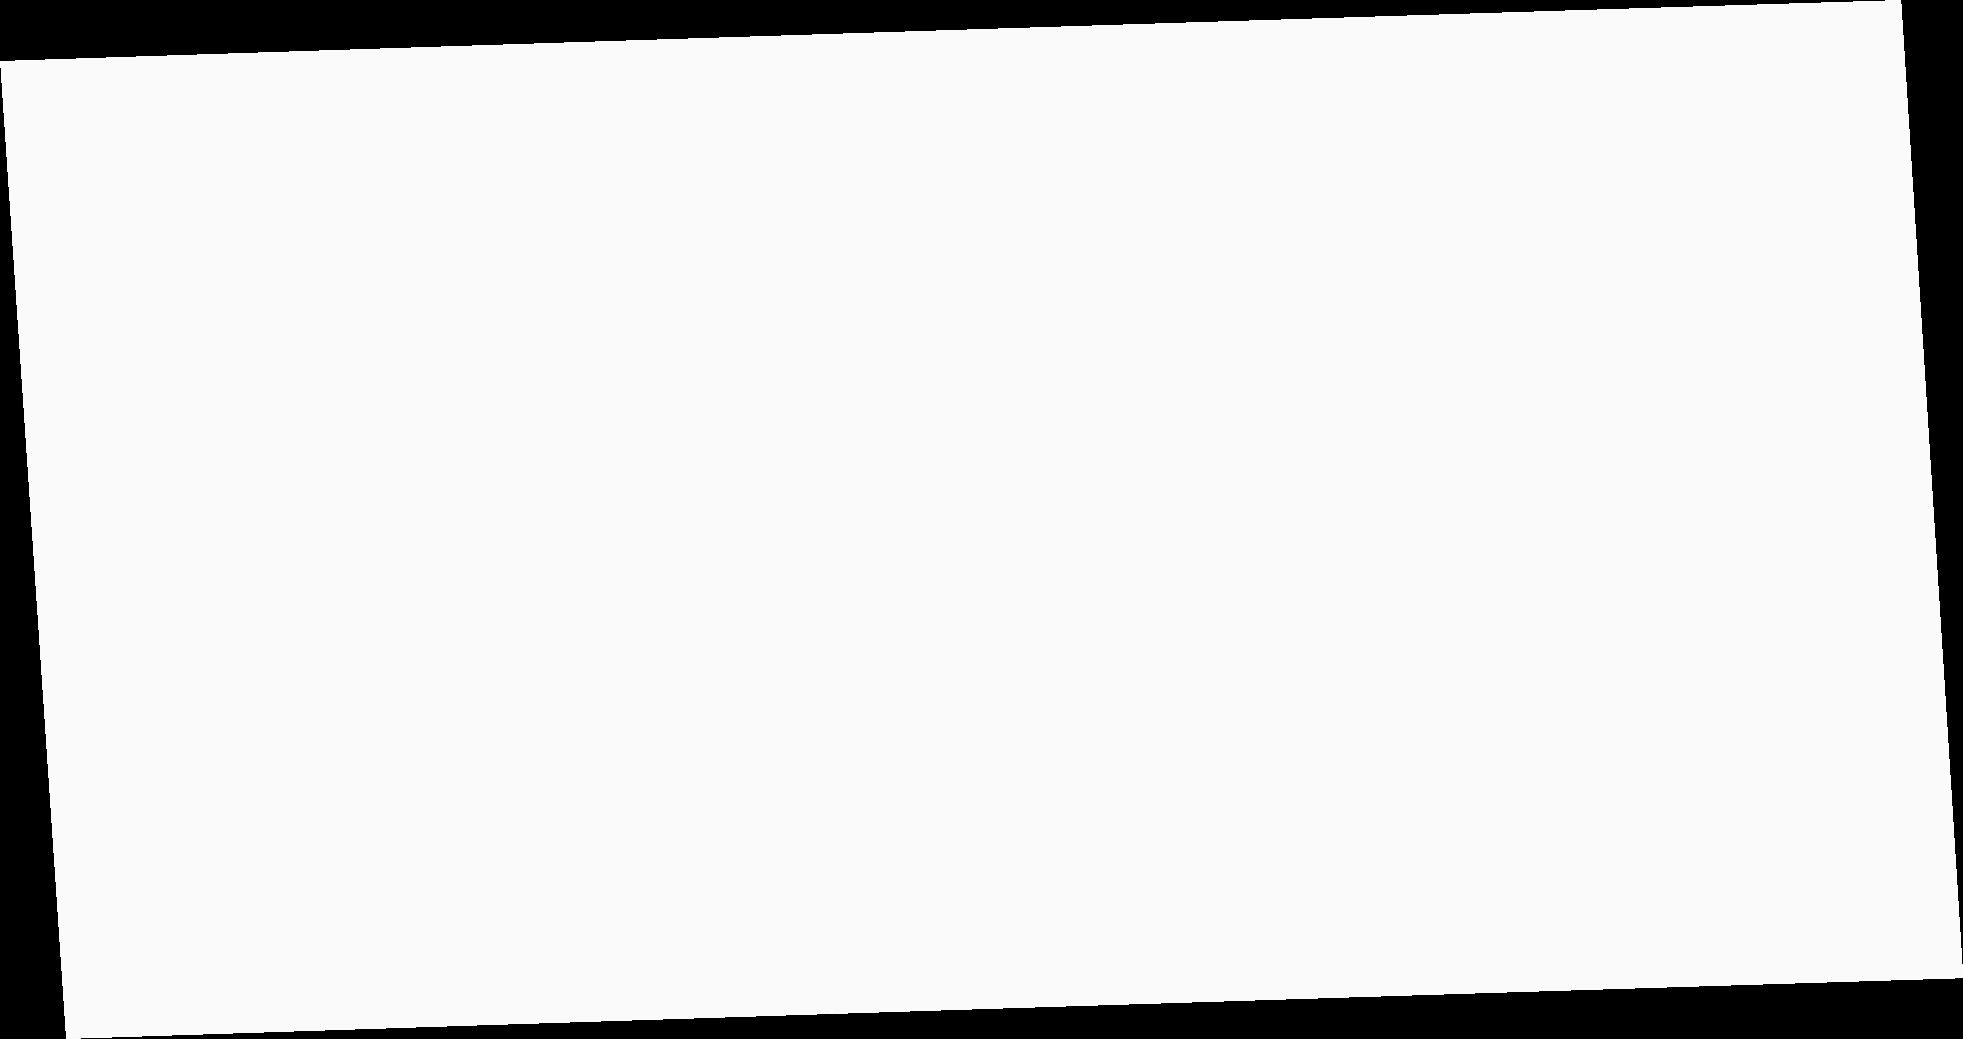

In [6]:
def subsets(out, asset):
    """Subset files of *asset* under *out*, oldest first, as {date: path}."""
    files = sorted(
        out.rglob(f"*_{asset}_sub-*.tif"), key=lambda p: p.parent.parent.name
    )
    return {p.parent.parent.name: p for p in files}


vv_files, vh_files = subsets(S1_OUT, "vv"), subsets(S1_OUT, "vh")
dates = list(vv_files)
print(dates)
viz.quick_view(vv_files[dates[-1]], overview_level=None)

### Flood composites

Water is a smooth surface that reflects the radar away: very low backscatter in both
polarisations (roughly VV < -18 dB). Two composites make that visible:

1. **Single date, R=VV, G=VH, B=VV-VH (dB).** Water is dark in every channel, so it
   stands out as black/dark blue, while vegetation (strong VH) is green and built
   areas are bright.
2. **Change composite, R=latest VV, G=B=reference VV (dB).** The reference is the
   median of the earlier dates. Pixels that were bright and are now dark (new water)
   turn **cyan**; pixels that got brighter turn red; unchanged ones stay grey.

In [7]:
def load_db(path):
    da = rioxarray.open_rasterio(path, masked=True).squeeze("band", drop=True)
    return 10 * np.log10(da.where(da > 0))


def save_rgb(bands, ranges, path):
    """Stretch three DataArrays to 0-255 and write them as a 3-band GeoTIFF."""
    scaled = [((b - lo) / (hi - lo)).clip(0, 1) for b, (lo, hi) in zip(bands, ranges)]
    rgb = xr.concat(scaled, dim="band").assign_coords(band=[1, 2, 3])
    rgb = (rgb.fillna(0) * 255).astype("uint8")
    rgb = rgb.rio.write_crs(bands[0].rio.crs)
    rgb.rio.to_raster(path)
    return path


vv = {d: load_db(p) for d, p in vv_files.items()}
vh = {d: load_db(p) for d, p in vh_files.items()}
first = vv[dates[0]]
vv = {d: a.rio.reproject_match(first) for d, a in vv.items()}
vh = {d: a.rio.reproject_match(first) for d, a in vh.items()}
latest = dates[-1]

comp_dir = S1_OUT / "composites"
comp_dir.mkdir(exist_ok=True)
rgb_path = save_rgb(
    [vv[latest], vh[latest], vv[latest] - vh[latest]],
    [(-25, 0), (-30, -5), (0, 15)],
    comp_dir / f"{latest}_vv_vh_ratio.tif",
)
viz.quick_view(rgb_path, band_indices=[1, 2, 3], overview_level=None)

ValueError: cannot convert float NaN to integer

In [ ]:
display_map = None
if len(dates) < 2:
    print("Need at least two dates for a change composite")
else:
    reference = xr.concat([vv[d] for d in dates[:-1]], dim="time").median("time")
    change_path = save_rgb(
        [vv[latest], reference, reference],
        [(-25, 0)] * 3,
        comp_dir / f"{latest}_vs_reference_change.tif",
    )
    display_map = viz.quick_view(
        change_path, band_indices=[1, 2, 3], overview_level=None
    )
display_map

### Water mask and flooded area

In [ ]:
WATER_DB = -18
water_now = vv[latest] < WATER_DB
if len(dates) > 1:
    water_before = (
        xr.concat([vv[d] < WATER_DB for d in dates[:-1]], dim="time").mean("time") > 0.5
    )
    flooded = water_now & ~water_before
    px_km2 = abs(float(first.rio.resolution()[0] * first.rio.resolution()[1])) / 1e6
    # CRS units are metres for UTM Subsets
    print(f"Newly flooded: {float(flooded.sum()) * px_km2:.2f} km2")
    flood_path = comp_dir / f"{latest}_flooded.tif"
    flooded.astype("uint8").rio.write_crs(first.rio.crs).rio.to_raster(flood_path)
    viz.quick_view(flood_path, overview_level=None)